In [1]:
import numpy as np
import matplotlib.pyplot as plt
from evaluation_metrics.calibration_error import calculate_calibration_error
from evaluation_metrics.total_variation_distance import dataset_tvd_binary, model_and_human_probs_from_scores
import dataset_generator.generate_dataset as generate_dataset
from utils.plot_utils import save_stitched_pvalue_histograms, plot_benchmark_results
BernoulliPanel = generate_dataset.BernoulliPanel

In [ ]:
# ---------------------------------------------------------------------
#                               Helpers 
# ---------------------------------------------------------------------
def _ytrue_ypred_from_labels_and_scores(
    Y: np.ndarray,          # shape (n_samples, n_rads) with {0,1}
    p_scores: np.ndarray,   # shape (n_samples,)
    evaluation_level: str,
):
    """
    Convert (labels matrix, per-case scores) into aligned (y_true, y_pred)
    using your same definitions:
      - case: majority vote per case
      - rater: flatten rater annotations and repeat per-case scores
    """
    if evaluation_level == "case":
        y_true = (Y.mean(axis=1) >= 0.5).astype(int)
        y_pred = p_scores.astype(float)
        return y_true, y_pred

    if evaluation_level == "rater":
        y_true = Y.reshape(-1).astype(int)
        y_pred = np.repeat(p_scores.astype(float), Y.shape[1])
        return y_true, y_pred

    raise ValueError(f"Unknown evaluation_level: {evaluation_level}")


def _compute_metrics(
        Y: np.ndarray,
        p_scores: np.ndarray,
        evaluation_metrics: list[dict],
        prefix: str,
        n_radiologists: int
    ):
    """
    Compute selected evaluation metrics from rater labels and per-case model scores.

    Supports:
      - "ece": case-level Expected Calibration Error
      - "adjusted_ece": case-level ECE after majority-vote transformation
      - "rater_ece": rater-level ECE (flattened labels, repeated case scores)
      - "tvd": total variation distance between model and human probability distributions

    Returns:
        dict: Mapping from metric key to scalar value, e.g.
              {f"{prefix}_ece": ..., f"{prefix}_tvd": ...}.
    """
    y_true, y_pred = _ytrue_ypred_from_labels_and_scores(
        Y=Y,
        p_scores=p_scores,
        evaluation_level="case",
    )

    out = {}
    for metric in evaluation_metrics:
        metric_name = metric.get("metric_name")

        if metric_name == "ece":
            n_bins = metric.get("n_bins", None)
            if n_bins is None:
                raise ValueError("n_bins must be specified for ece.")
            out[f"{prefix}_ece"] = calculate_calibration_error(y_true=y_true, y_pred=y_pred, n_bins=n_bins, save_curve_filepath=None)

        elif metric_name == "adjusted_ece":
            n_bins = metric.get("n_bins", None)
            if n_bins is None:
                raise ValueError("n_bins must be specified for ece.")
            
            ######### Apply g(n) transformation to y_pred #########
            from scipy.stats import binom
            num_raters = n_radiologists
            majority_threshold = num_raters // 2
            y_pred = 1 - binom.cdf(majority_threshold, num_raters, y_pred)
            ########################################################
            out[f"{prefix}_adjusted_ece"] = calculate_calibration_error(y_true=y_true, y_pred=y_pred, n_bins=n_bins, save_curve_filepath=None)

        elif metric_name == "rater_ece":
            n_bins = metric.get("n_bins", None)
            if n_bins is None:
                raise ValueError("n_bins must be specified for rater_ece.")

            ##### Flatten to rater-level and repeat per-case scores for y_pred #####
            y_true_rater, y_pred_rater = _ytrue_ypred_from_labels_and_scores(
                Y=Y,
                p_scores=p_scores,
                evaluation_level="rater",
            )
            #########################################################################
            out[f"{prefix}_rater_ece"] = calculate_calibration_error(
                y_true=y_true_rater,
                y_pred=y_pred_rater,
                n_bins=n_bins,
                save_curve_filepath=None,
            )

        elif metric_name == "tvd":
            model_prob, human_prob = model_and_human_probs_from_scores(Y, p_scores)
            tvd = dataset_tvd_binary(model_prob=model_prob, human_prob=human_prob)
            out[f"{prefix}_tvd"] = tvd
            
        else:
            raise ValueError(f"Unknown metric name: {metric_name}")

    return out


class SubjectivityBenchmark:
    """
    Monte Carlo benchmark for synthetic subjectivity worlds.

    For each simulation and each world `w` in `self.worlds`:
      - Generate latent per-case probabilities using the world spec (`a`, etc.)
        via `BernoulliPanel.generate_bimodal_power_plist`.
      - Sample rater labels `Y_w` from those probabilities.
      - Evaluate configured metrics on the within-world pairing `(p_w, Y_w)`.
    """

    def __init__(
        self,
        worlds: dict,  # {world_name: {"a":.., "n0":.., "clip_eps":.., "shuffle":..}, ...}
        n_samples: int,
        n_radiologists: int,
        evaluation_metrics: list[dict],
        n_simulations: int = 200,
        base_seed: int | None = 42,
    ):
        if not isinstance(worlds, dict) or len(worlds) < 1:
            raise ValueError("worlds must be a non-empty dict of world_name to spec dict.")

        # Keep insertion order (Py3.7+) so output is stable/deterministic.
        self.worlds = {}
        for name, spec in worlds.items():
            if not isinstance(spec, dict):
                raise ValueError(f"World '{name}' spec must be a dict.")
            self.worlds[str(name)] = {k: float(v) for k, v in spec.items()}
        self.world_names = list(self.worlds.keys())

        self.n_samples = int(n_samples)
        self.n_radiologists = int(n_radiologists)
        self.evaluation_metrics = evaluation_metrics
        self.n_simulations = int(n_simulations)
        self.base_seed = base_seed

        self.results = {}  # aggregated lists across sims

    def _create_dataset_generator(self, spec,  random_seed: int | None = None):
        """
        Create and return a ``BernoulliPanel`` dataset generator for one synthetic world.

        Args:
            spec (dict): World configuration. Must include key ``"a"`` for
            ``generate_bimodal_power_plist`` and may include optional keys
            ``"n0"``, ``"clip_eps"``, and ``"shuffle"``.
            random_seed (int | None): Seed used for reproducible sampling.

        Returns:
            BernoulliPanel: Generator with latent probabilities and sampled
            rater labels already created via ``generate_dataset()``.
        """
        panel_beta = BernoulliPanel(
            n_radiologists=self.n_radiologists,
            n_samples=self.n_samples,
            random_seed=random_seed,
        )
        
        if "a" in spec:
            panel_beta.generate_bimodal_power_plist(
                a=spec["a"],
                n0=spec.get("n0", None),
                clip_eps=spec.get("clip_eps", None),
                shuffle=spec.get("shuffle", True),
            )
        else:
            raise ValueError("World spec must include 'a' parameter for bimodal subjectivity distribution.")
        
        panel_beta.generate_dataset()
        return panel_beta

    @staticmethod
    def _create_rater_labels_vector(panel: BernoulliPanel):
        """
        Creates the rater labels vector: shape (n_samples, n_radiologists)
        Assumes that columns containing rater labels start with y
        """
        rater_label_cols = [col for col in panel.df.columns if col.startswith("y")]
        Y = panel.df[rater_label_cols].values
        return Y

    def _one_simulation(self, rng: np.random.Generator):
        # Generate panels per world
        p_by_world = {}
        Y_by_world = {}

        for w in self.world_names:
            spec = self.worlds[w]
            panel = self._create_dataset_generator(
                spec,
                random_seed=rng.integers(1e9),
            )
            p_by_world[w] = panel.df["p"].values
            Y_by_world[w] = self._create_rater_labels_vector(panel)

            assert Y_by_world[w].shape == (self.n_samples, self.n_radiologists)

        save_stitched_pvalue_histograms(
            worlds=self.worlds,
            p_by_world=p_by_world,
            basepath="./results/",
            filename="synthetic_worlds_pvalue_histograms",
            bins=30,
            density=True,      # set True if you want shape comparability
        )

        # Evaluate metrics for each world pairing (p_world, y_world)
        sim_out = {}
        for w in self.world_names:
            metrics_out = _compute_metrics(
                Y=Y_by_world[w],
                p_scores=p_by_world[w],
                evaluation_metrics=self.evaluation_metrics,
                prefix=f"p{w}_y{w}",
                n_radiologists=self.n_radiologists,
            )
            sim_out.update(metrics_out)

        return sim_out

    def run(self):
        for sim_idx in range(self.n_simulations):
            seed = None if self.base_seed is None else (self.base_seed + sim_idx)
            rng = np.random.default_rng(seed)

            sim_out = self._one_simulation(rng)

            for k, v in sim_out.items():
                self.results.setdefault(k, []).append(v)

        return self.results


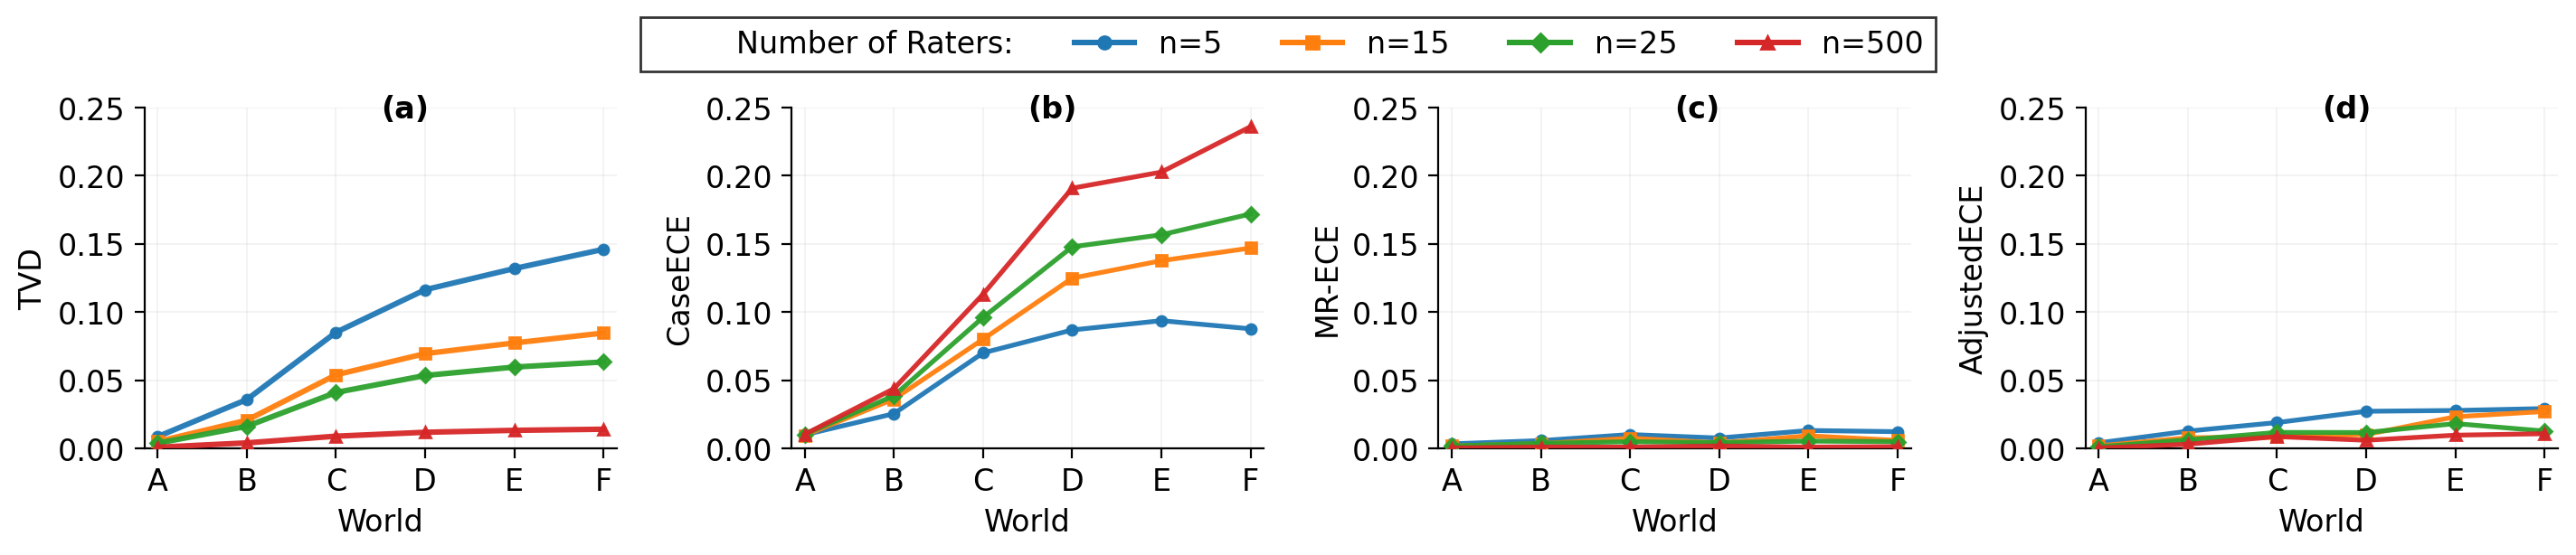

In [ ]:
def extract_metric_series(results: dict, worlds_in_order: list[str]):
    key_map = {
        "tvd":          lambda w: f"p{w}_y{w}_tvd",
        "case_ece":     lambda w: f"p{w}_y{w}_ece",
        "adjusted_ece": lambda w: f"p{w}_y{w}_adjusted_ece",
        "rater_ece":    lambda w: f"p{w}_y{w}_rater_ece",
    }
    out = {}
    for m, key_fn in key_map.items():
        out[m] = np.asarray([float(results[key_fn(w)][0]) for w in worlds_in_order])
    return out


def run_benchmark_experiments(
    worlds: dict,
    n_samples: int,
    n_raters_list: tuple[int],
    base_seed: int = 42,
    n_simulations: int = 1,    
):
    diag_metrics = [
        {"metric_name": "tvd"},
        {"metric_name": "ece", "n_bins": 10},
        {"metric_name": "rater_ece", "n_bins": 10},
        {"metric_name": "adjusted_ece", "n_bins": 10},
    ]

    worlds_in_order = list(worlds.keys())
    
    all_series = {}
    for nr in n_raters_list:
        exp = SubjectivityBenchmark(
            worlds=worlds,
            n_samples=n_samples,
            n_radiologists=int(nr),
            evaluation_metrics=diag_metrics,
            n_simulations=n_simulations,
            base_seed=base_seed,
        )
        results = exp.run()
        all_series[nr] = extract_metric_series(
            results=results,
            worlds_in_order=worlds_in_order,
        )

    return all_series


# ------------------------------------------------------------
# Run benchmark experiment
# ------------------------------------------------------------
worlds = {
    "A": {"a": 50},
    "B": {"a": 10},
    "C": {"a": 3},
    "D": {"a": 1.5},
    "E": {"a": 1.2},
    "F": {"a": 1.0},
}
n_raters_list = (5, 15, 25, 500)

all_series = run_benchmark_experiments(
      worlds=worlds,
      n_samples=1000,
      n_raters_list=n_raters_list,
      base_seed=42,
      n_simulations=1,
  )
  
fig, (ax_abs, ax_case, ax_rater, ax_adj) = plot_benchmark_results(
    worlds=worlds,
    all_series=all_series,
    n_raters_list=n_raters_list,
    save_path="./results/benchmark_results.png",
)
plt.show()